In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

In [3]:
params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [4]:
#Color-blind friendly pallete
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B"   # Muted Purple
]

vib_blue = "#0C7BDC"
teal = "#40B0A6"
purple = "#5D3A9B" 

dot_scale = 500

In [5]:
solar_system_df = pd.read_csv('solarsystem.csv')
mercury = solar_system_df[solar_system_df['name'] == 'Mercury']
venus = solar_system_df[solar_system_df['name'] == 'Venus']
earth = solar_system_df[solar_system_df['name'] == 'Earth']
mars = solar_system_df[solar_system_df['name'] == 'Mars']

In [6]:
base_path = "/Users/honeyeah/Codes/data/" #folder with all data


sim_set = "cham_cont/" #name of simulation set, folder with subfolders the name "sim_set_i"
sim_archive_path = base_path + sim_set + "cham_cont_" #path given to get_runtime_data function
cham_cont_rdf = rr.get_runtime_data(sim_archive_path, 50, "cham_cont_") #rdf is runtime data frame


cut_time = 299.9e6

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.10.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: Ru

In [7]:
n_runs = 50

maxtimes_cham_cont = np.array([
    cham_cont_rdf[cham_cont_rdf['simulation_id'] == i + 1]['time'].max()
    for i in range(n_runs)
])

keep_cham_cont = np.where(maxtimes_cham_cont > 299.9e6)[0]

print("number of finished runs\n")
print(f"cham_cont: {len(keep_cham_cont)}")

number of finished runs

cham_cont: 22


In [15]:
keep_cham_cont

array([ 0,  1,  2,  3,  4,  5,  7,  8,  9, 25, 26, 28, 29, 31, 32, 33, 34,
       35, 36, 37, 38, 45])

In [8]:
#FOR cham_cont
cut_times = [10*10**6,  20e6, 50e6, 100e6, 299.9e6]
cham_cont_u_dataframes = []

for cut in cut_times:
    cham_cont_ppdf_list = rr.get_particle_params_at_time(
        f"/Users/honeyeah/Codes/data/cham_cont/cham_cont_", keep_cham_cont, "cham_cont_", cut
    )

    cham_cont_u_pldf_list = []
    for j, i in enumerate(keep_cham_cont):
        df = rr.read_dbct_output(
        f"/Users/honeyeah/Codes/data/cham_cont/cham_cont_{i+1}/animation/uniform_33_{int(cut/1e6)}Myrs.txt",
        0.3, "none", "none"
        )

        df_len = len(df)  
        param_len = len(cham_cont_ppdf_list[j])
        min_len = min(df_len, param_len)

        if min_len == 0:
            print(f"Skipping index {i}: empty df or param list.")
            continue

        # Trim both to same length
        df = df.iloc[:min_len].copy()
        semi_values = cham_cont_ppdf_list[j]['semi'][:min_len]
        df['semi'] = semi_values.values  # if semi_values is a Series
        df['sim_id'] = i + 1

        cham_cont_u_pldf_list.append(df)
        df_at_snapshot = pd.concat(cham_cont_u_pldf_list)
        df_at_snapshot['time'] = cut
        cham_cont_u_dataframes.append(df_at_snapshot)

cham_cont_u_pdframe = pd.concat(cham_cont_u_dataframes)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.10.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: Ru

In [9]:
#Step function
cham_cont_s_dataframes = []

for cut in cut_times:
    cham_cont_ppdf_list = rr.get_particle_params_at_time(
        f"/Users/honeyeah/Codes/data/cham_cont/cham_cont_", keep_cham_cont, "cham_cont_", cut
    )

    cham_cont_s_pldf_list = []
    for j, i in enumerate(keep_cham_cont):
        df = rr.read_dbct_output(
        f"/Users/honeyeah/Codes/data/cham_cont/cham_cont_{i+1}/animation/step_b0.7_p0.20_{int(cut/1e6)}Myrs.txt",
        0.3, "none", "none"
        )

        df_len = len(df)  
        param_len = len(cham_cont_ppdf_list[j])
        min_len = min(df_len, param_len)

        if min_len == 0:
            print(f"Skipping index {i}: empty df or param list.")
            continue

        # Trim both to same length
        df = df.iloc[:min_len].copy()
        semi_values = cham_cont_ppdf_list[j]['semi'][:min_len]
        df['semi'] = semi_values.values  # if semi_values is a Series
        df['sim_id'] = i + 1

        cham_cont_s_pldf_list.append(df)
        df_at_snapshot = pd.concat(cham_cont_s_pldf_list)
        df_at_snapshot['time'] = cut
        cham_cont_s_dataframes.append(df_at_snapshot)

cham_cont_s_pdframe = pd.concat(cham_cont_s_dataframes)


/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.10.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: Ru

In [10]:
cham_cont_u_pdframe[(cham_cont_u_pdframe['time'] == cut_times[0])]

,hash,mass,cmf,tot_disk_cmf,boundary,percentage,semi,sim_id,time
0,1.000000e+00,3.571414e-09,0.33000,0.3,none,none,0.468926,1,10000000.0
1,2.000000e+00,1.031458e-08,0.33000,0.3,none,none,0.650959,1,10000000.0
2,5.000000e+00,3.652278e-07,0.32997,0.3,none,none,0.866365,1,10000000.0
3,1.100000e+01,1.400000e-08,1.00000,0.3,none,none,0.827710,1,10000000.0
4,1.200000e+01,5.261421e-08,0.33000,0.3,none,none,0.657118,1,10000000.0
...,...,...,...,...,...,...,...,...,...
94,3.104813e+08,1.474268e-08,0.00000,0.3,none,none,0.918415,46,10000000.0
95,5.511377e+08,1.474268e-08,0.00000,0.3,none,none,0.569536,46,10000000.0
96,1.218250e+09,1.474268e-08,0.00000,0.3,none,none,1.470971,46,10000000.0
97,1.035956e+09,1.756008e-08,0.00000,0.3,none,none,1.528501,46,10000000.0


In [11]:
cut_times

[10000000, 20000000.0, 50000000.0, 100000000.0, 299900000.0]

In [12]:
plt.figure(figsize=(5,20))
times_labels = [10e6, 20e6, 50e6, 100e6, 300e6]



<Figure size 500x2000 with 0 Axes>

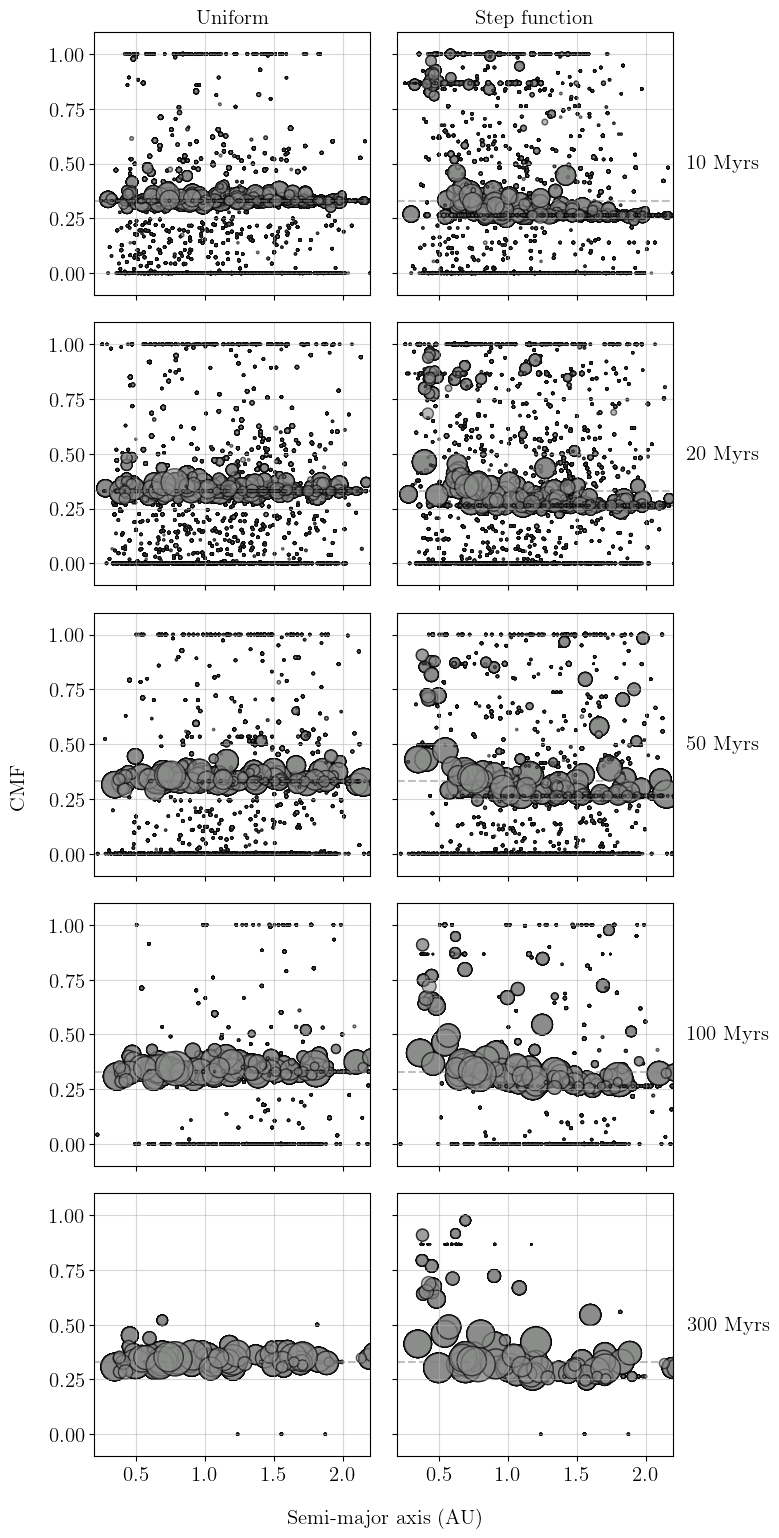

In [13]:
fig, axes = plt.subplots(5, 2, figsize=(8, 16), sharey=True, sharex=True)

datasets = []

times_to_plot = [10e6, 20e6, 50e6, 100e6, 299.9e6]
times_labels = [10e6, 20e6, 50e6, 100e6, 300e6]

for t in times_to_plot:
    label_time = int(t / 1e6)  # for display purposes
    datasets.append((f"Cham2013 bimod, Uniform, {label_time} Myrs", cham_cont_u_pdframe[cham_cont_u_pdframe['time'] == t], colors[3]))
    datasets.append((f"Cham2013 bimod, Step function, {label_time} Myrs", cham_cont_s_pdframe[cham_cont_s_pdframe['time'] == t], colors[3]))


row_labels = [f"{int(t/1e6)} Myrs" for t in times_labels]
col_labels = ["Uniform", "Step function"]


for i, (label, df, color) in enumerate(datasets):
    ax = axes.flat[i]
    ax.grid(True, alpha=0.5)
    ax.plot([0.2, 2.2], [0.33, 0.33], linestyle='dashed', color='grey', alpha=0.5)

    ax.scatter(df['semi'], df['cmf'], alpha=0.6, color=color,
               edgecolors='black', linewidths=1,
               s=df['mass'] * sol_to_earth * dot_scale, rasterized=True)

    ax.set_xlim(0.2, 2.2)
    ax.set_ylim(-0.1, 1.1)

    row = i // 2
    col = i % 2

    # Add column titles only in the first row
    if row == 0:
        ax.set_title(col_labels[col])

    # Add row labels only in the first column
    # Add row labels only in the last column (right side)
    # Add row labels only in the last column (right side)
    if col == 1:
        ax.annotate(row_labels[row],
                xy=(1, 0.5), xytext=(ax.yaxis.labelpad + 212, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='medium', ha='left', va='center', rotation=0)





# Shared axis labels
fig.text(0.5, 0.04, 'Semi-major axis (AU)', ha='center')
fig.text(0.03, 0.5, r'CMF', va='center', rotation='vertical')

#fig.suptitle('Uniform CMF distributions (0.33)')
plt.tight_layout(rect=[0.05, 0.05, 1, 1])

plt.savefig("paper_plots/snapshots_cham_cont.pdf", dpi=300)  # or .png

plt.show()

In [ ]:
simulation = rebound.Simulationarchive("/Users/honeyeah/Codes/data/cham_cont/cham_cont_1/cham_cont_1")

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.10.
  warnings.warn(message, RuntimeWarning)


In [21]:
len(simulation)

3001

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Encountered unknown field in file. File might have been saved with a different version of REBOUND.
  warnings.warn(message, RuntimeWarning)


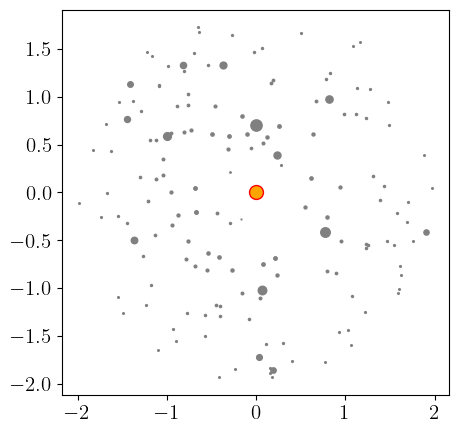

In [35]:
snap = simulation[0]
plt.figure(figsize=(5,5))
plt.scatter(0, 0, s = 100, color = 'orange', edgecolors='red')

for i in range(1, snap.N -2):
    plt.scatter(snap.particles[i].x, snap.particles[i].y, s = snap.particles[i].m * 1e8, color = 'gray')


plt.show()

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Encountered unknown field in file. File might have been saved with a different version of REBOUND.
  warnings.warn(message, RuntimeWarning)


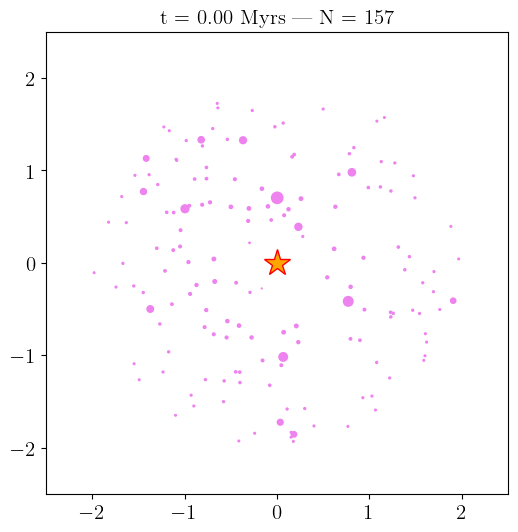

MovieWriter ffmpeg unavailable; using Pillow instead.
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Encountered unknown field in file. File might have been saved with a different version of REBOUND.
  warnings.warn(message, RuntimeWarning)


In [64]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np

# Create figure
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_aspect('equal')

# Plot the central star
star, = ax.plot(0, 0, marker='*', color='orange', markersize=20, markeredgecolor='red')

# Placeholder for particles
scat = ax.scatter([], [], s=[], color='violet')

# Update function for animation
def update(frame):
    snap = simulation[frame]

    x, y, sizes = [], [], []
    for i in range(1, snap.N - 2):
        p = snap.particles[i]
        if p.m < 1e-5:
            p = snap.particles[i]
            x.append(p.x)
            y.append(p.y)
            sizes.append(p.m * 1e8)

    scat.set_offsets(np.column_stack((x, y)))
    scat.set_sizes(sizes)
    ax.set_title(f"t = {snap.t/1e6:.2f} Myrs  |  N = {snap.N}")

    return scat,

# Create the animation
frames = range(0, 3001, 20)
ani = FuncAnimation(fig, update, frames=frames, interval=50, blit=True)

# Show animation
plt.show()

# Optional: save animation
ani.save('formation_disk_sim.gif', fps=10)


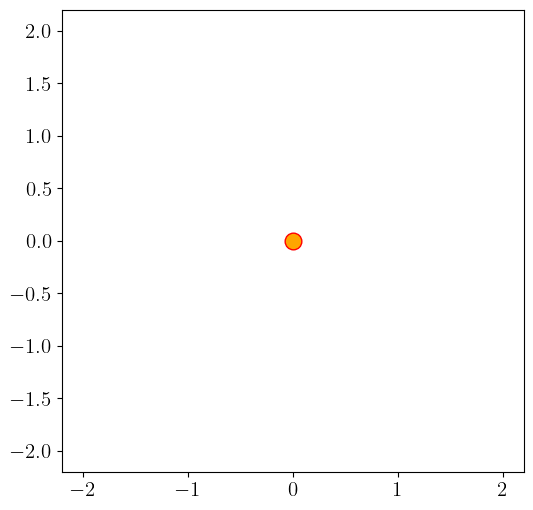

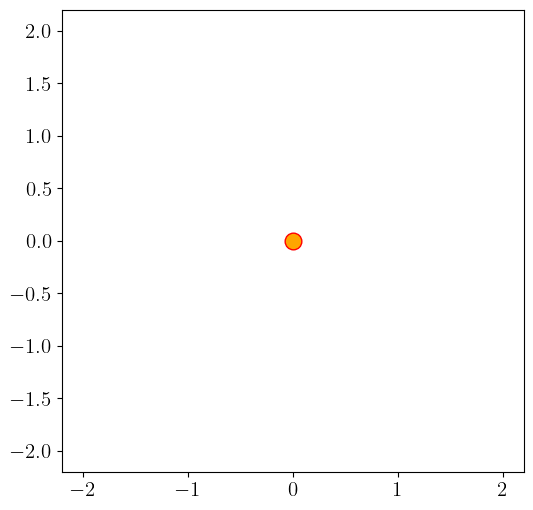

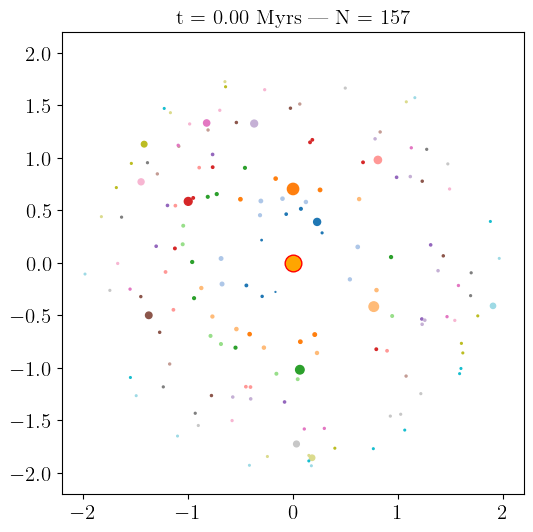

MovieWriter ffmpeg unavailable; using Pillow instead.
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Encountered unknown field in file. File might have been saved with a different version of REBOUND.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved wi

In [43]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np

# Create figure
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-2.2, 2.2)
ax.set_ylim(-2.2, 2.2)
ax.set_aspect('equal')

# Plot the central star
star, = ax.plot(0, 0, 'o', color='orange', markersize=12, markeredgecolor='red')

# Placeholder for particles
scat = ax.scatter([], [], s=[])

# Update function for animation
def update(frame):
    snap = simulation[frame]
    x, y, sizes, hashes = [], [], [], []

    for i in range(1, snap.N - 2):
        p = snap.particles[i]
        x.append(p.x)
        y.append(p.y)
        sizes.append(p.m * 1e8)
        # Convert hash (c_uint) → int
        hashes.append(int(p.hash.value) if hasattr(p.hash, 'value') else int(p.hash))

    hashes = np.array(hashes, dtype=float)

    # normalize hashes for colormap
    if len(hashes) > 0:
        norm_hash = (hashes - hashes.min()) / (hashes.max() - hashes.min() + 1e-12)
        colors = plt.cm.tab20(norm_hash)  # try 'turbo' or 'hsv' for smoother colors
    else:
        colors = []

    scat.set_offsets(np.column_stack((x, y)))
    scat.set_sizes(sizes)
    scat.set_color(colors)
    ax.set_title(f"t = {snap.t/1e6:.2f} Myrs  |  N = {snap.N}")

    return scat,

# Create the animation
frames = range(0, 3001, 20)  # every 20th snapshot
ani = FuncAnimation(fig, update, frames=frames, interval=50, blit=True)

# Show animation
plt.show()

# Optional: save animation
ani.save('formation_disk_sim.gif', fps=10)
